---
title: "Quant Trading: Asset Class Selection"
author: "Fabian"
date: "2024-04-12"
categories: [Trading, Quant]
---


# Unlocking Your Trading Potential through Data Analytics

As a seasoned quantitative trader who relies on statistical analysis to thrive in the dynamic world of trading, one of the fundamental questions that drives my strategy is: "What should I prioritize in my trades?" While many traders instinctively gravitate towards high-leverage asset classes in pursuit of maximum profit potential, the real question lies in whether this approach truly amplifies expected returns or simply magnifies risks.

Successful trading isn't just about occasional windfalls; it's about consistent profitability. Achieving this demands a crystal-clear understanding of both risk exposure and potential returns.

Instead of fixating solely on leverage, the pivotal inquiry for traders like us becomes: "Where do the most promising opportunities lie?" This question is pivotal, holding the key to unlocking sustained success and profitability in trading endeavors.

Timing is undeniably central to trading prowess. Being in the right asset class can tell you your expected returns and knowing how long your trade will last reduces your risk. But discerning the optimal asset class and timing isn't an endeavor governed by intuition alone. It demands a rigorous interrogation of data and statistical insights.

In this blog post, I'll dive into a recent project where I meticulously analyzed the distribution of returns across a diverse spectrum of assets, encompassing bond ETFs, currencies, equity indices, and various sectors. This examination spanned daily, weekly, and monthly time frames, aiming to uncover actionable insights that can inform savvy trading decisions.

Join me as we leverage the power of data analytics to discern the asset classes and temporal windows offering the most promising growth potential for traders like yourself.


## Exploring the Data

To begin, I gathered historical data for a diverse set of assets, spanning bond ETFs, currencies, equity indices, and sector-specific stocks. I used the yfinance library in Python to download years of daily adjusted close data for these tickers.

In [1]:
import pandas as pd
import numpy as np
import yfinance as yf

In [2]:
start = '1970-04-01'
end = '2023-04-01'


In [3]:
asset_classes = {
    'Mid-Cap Stocks': ['MDY', 'IJH', 'XMLV'],
    'Mega-Cap Stocks': ['SPY', 'QQQ', 'DIA'],
    'Technology': ['XLK', 'VGT', 'FTEC'],
    'Healthcare': ['XLV', 'VHT', 'IYH'],
    'Financials': ['XLF', 'VFH', 'IYF'],
    'Bonds': ['AGG', 'TLT', 'BND'],
    'Commodities': ['GLD', 'USO', 'DBC'],
    'Real Estate': ['VNQ', 'SCHH', 'XLRE']
}

## The following code will download the data for the selected assets

In [4]:
# downaload the dat adn save into data folder
# for asset_class, tickers in asset_classes.items():
#     for ticker in tickers:
#         data = yf.download(ticker, start=start, end=end)
#         data.to_csv(f'data/{ticker}.csv')
#         print(f'{ticker} downloaded')


## Lets do a quick Walk through of one csv file so you can see what the data looks like and how we want to handle it.

In [5]:
# download BND data into a dataframe
bnd = pd.read_csv('data/BND.csv', index_col='Date', parse_dates=True)

In [6]:
bnd = bnd.sort_index(ascending=False)

In [7]:
bnd.head()

,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
2023-03-31,73.589996,73.870003,73.470001,73.830002,71.255219,4549200
2023-03-30,73.320000,73.519997,73.320000,73.449997,70.888474,3455300
2023-03-29,73.160004,73.419998,73.150002,73.349998,70.791946,4231300
2023-03-28,73.260002,73.370003,73.199997,73.269997,70.714745,3473300
2023-03-27,73.599998,73.730003,73.400002,73.400002,70.840202,5769800


In [8]:
# new columns close to close daily returns , high to low daily returnsm, and open to close daily returns 
bnd['close_to_close'] = bnd['Close'].pct_change().fillna(method='bfill')
bnd['daily_high_low'] = bnd['High'] / bnd['Low'] - 1
bnd['daily_open_close'] = bnd['Close'] / bnd['Open'] - 1


/var/folders/nq/y2lyg7p15txfm5ksrw6f90340000gn/T/ipykernel_95669/154206485.py:2: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  bnd['close_to_close'] = bnd['Close'].pct_change().fillna(method='bfill')


In [9]:
bnd.head()

,Open,High,Low,Close,Adj Close,Volume,close_to_close,daily_high_low,daily_open_close
Date,,,,,,,,,
2023-03-31,73.589996,73.870003,73.470001,73.830002,71.255219,4549200,-0.005147,0.005444,0.003261
2023-03-30,73.320000,73.519997,73.320000,73.449997,70.888474,3455300,-0.005147,0.002728,0.001773
2023-03-29,73.160004,73.419998,73.150002,73.349998,70.791946,4231300,-0.001361,0.003691,0.002597
2023-03-28,73.260002,73.370003,73.199997,73.269997,70.714745,3473300,-0.001091,0.002322,0.000136
2023-03-27,73.599998,73.730003,73.400002,73.400002,70.840202,5769800,0.001774,0.004496,-0.002717


In [10]:
# dropo nan values
bnd = bnd.dropna()



In [11]:
from IPython.display import display
# distribution of returns line for close_to_close, daily_high_low, and daily_open_close overlayed on the same plotly plot
import plotly.graph_objects as go
fig = go.Figure()

fig.add_trace(go.Histogram(x=bnd['close_to_close'], histnorm='probability', name='Close to Close'))
fig.add_trace(go.Histogram(x=bnd['daily_high_low'], histnorm='probability', name='Daily High Low'))
fig.add_trace(go.Histogram(x=bnd['daily_open_close'], histnorm='probability', name='Daily Open Close'))

fig.update_traces(opacity=0.65)
fig.update_layout(barmode='overlay')
fig.update_layout(title='Distribution of Returns', xaxis_title='Return', yaxis_title='Density')


display(fig)



In [12]:
# pritn tabel of summary statistics for close_to_close, daily_high_low, and daily_open_close
summary = bnd[['close_to_close', 'daily_high_low', 'daily_open_close']].describe()
print(summary.to_string(float_format='%.4f'))



       close_to_close  daily_high_low  daily_open_close
count       4024.0000       4024.0000         4024.0000
mean           0.0000          0.0032           -0.0000
std            0.0033          0.0050            0.0027
min           -0.0405          0.0000           -0.0377
25%           -0.0016          0.0016           -0.0011
50%           -0.0001          0.0024            0.0000
75%            0.0015          0.0035            0.0010
max            0.0575          0.2075            0.0403


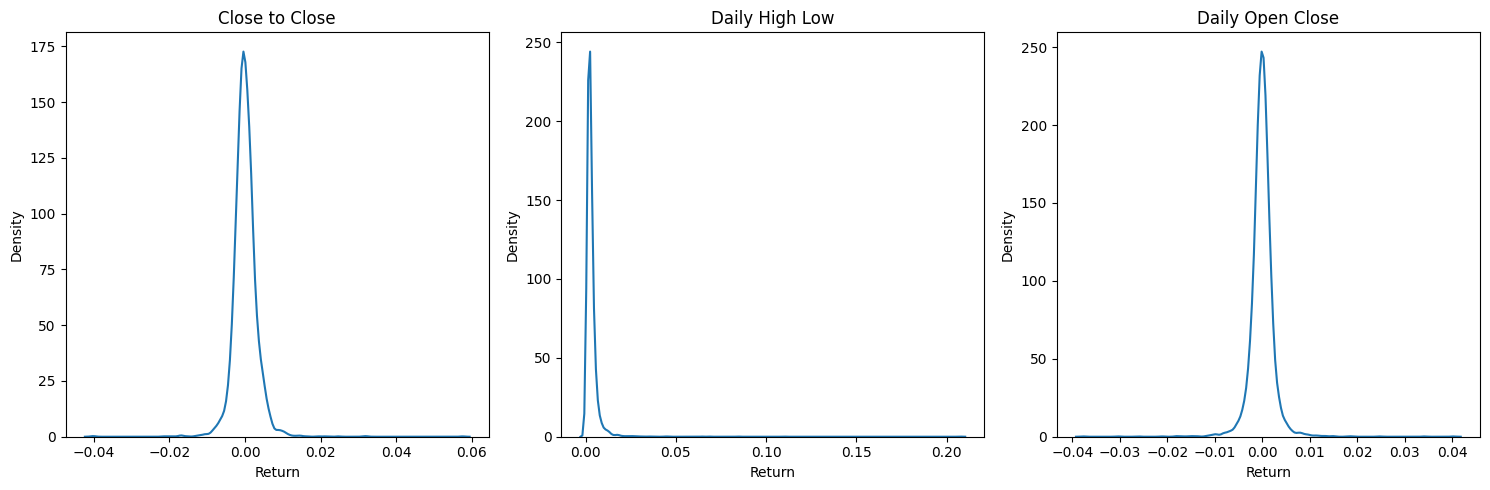

In [13]:
# plot using kde
import seaborn as sns
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 3, figsize=(15, 5))

sns.kdeplot(bnd['close_to_close'], ax=ax[0])
ax[0].set_title('Close to Close')
ax[0].set_xlabel('Return')

sns.kdeplot(bnd['daily_high_low'], ax=ax[1])
ax[1].set_title('Daily High Low')
ax[1].set_xlabel('Return')

sns.kdeplot(bnd['daily_open_close'], ax=ax[2])
ax[2].set_title('Daily Open Close')
ax[2].set_xlabel('Return')

plt.tight_layout()
plt.show()

## Review

As you can see the we are looking at 3 different values close to close, high to high, and low to low. We will be using the close to close values for our analysis. so that we can understand the whole trading day and after hours. Notice how the daily open to close volatility is pretty low. if your day trading then you are constrained by the open to close volatility. 


If you have to pay a fee for a round trip trade of even worse if have zero commisino trding and someoneis front runnign your order flow then you are going to have a bad time. the deck is stacked agains you



# Lets build out groups of daily returns. 

In [14]:
# Function to compute daily returns
def get_daily_returns(tickers):
    data = yf.download(tickers, start='2021-01-01', end='2023-12-31')
    returns = data['Adj Close'].pct_change().dropna(how='all', axis=1)
    return returns

In [15]:


# Function to compute weekly returns
def get_weekly_returns(tickers):
    data = yf.download(tickers, start='2021-01-01', end='2023-12-31')
    returns = data['Adj Close'].pct_change().dropna(how='all', axis=1)
    weekly_returns = returns.resample('W').last().pct_change()
    return weekly_returns



In [16]:
# dislay the asset claas distributions for daily returns
for asset_class, tickers in asset_classes.items():
    returns = get_daily_returns(tickers)
    fig = go.Figure()
    for ticker in returns.columns:
        fig.add_trace(go.Histogram(x=returns[ticker], histnorm='probability', name=ticker))
    fig.update_traces(opacity=0.65)
    fig.update_layout(barmode='overlay')
    fig.update_layout(title=f'{asset_class} Daily Returns', xaxis_title='Return', yaxis_title='Density')
    display(fig)

    

[*********************100%%**********************]  3 of 3 completed


[*********************100%%**********************]  3 of 3 completed


[*********************100%%**********************]  3 of 3 completed


[*********************100%%**********************]  3 of 3 completed


[*********************100%%**********************]  3 of 3 completed


[*********************100%%**********************]  3 of 3 completed


[*********************100%%**********************]  3 of 3 completed


[*********************100%%**********************]  3 of 3 completed


In [17]:
# doensload and siplay weekly returns for asset classes
for asset_class, tickers in asset_classes.items():
    returns = get_weekly_returns(tickers)
    fig = go.Figure()
    for ticker in returns.columns:
        fig.add_trace(go.Histogram(x=returns[ticker], histnorm='probability', name=ticker))
    fig.update_traces(opacity=0.65)
    fig.update_layout(barmode='overlay')
    fig.update_layout(title=f'{asset_class} Weekly Returns', xaxis_title='Return', yaxis_title='Density')
    display(fig)



[*********************100%%**********************]  3 of 3 completed


[*********************100%%**********************]  3 of 3 completed


[*********************100%%**********************]  3 of 3 completed


[*********************100%%**********************]  3 of 3 completed


[*********************100%%**********************]  3 of 3 completed


[*********************100%%**********************]  3 of 3 completed


[*********************100%%**********************]  3 of 3 completed


[*********************100%%**********************]  3 of 3 completed


In [18]:
# print the summary statistics for daily returns
for asset_class, tickers in asset_classes.items():
    returns = get_daily_returns(tickers)
    summary = returns.describe()
    print(f'{asset_class} Daily Returns')
    print(summary.to_string(float_format='%.4f'))
    print('\n')

[*********************100%%**********************]  3 of 3 completed
[*********************100%%**********************]  3 of 3 completed
[*********************100%%**********************]  3 of 3 completed
[*********************100%%**********************]  3 of 3 completed
[*********************100%%**********************]  3 of 3 completed
[*********************100%%**********************]  3 of 3 completed


Mid-Cap Stocks Daily Returns
Ticker      IJH      MDY     XMLV
count  752.0000 752.0000 752.0000
mean     0.0004   0.0004   0.0003
std      0.0131   0.0132   0.0097
min     -0.0488  -0.0474  -0.0365
25%     -0.0083  -0.0083  -0.0056
50%      0.0003   0.0003   0.0004
75%      0.0086   0.0087   0.0059
max      0.0579   0.0580   0.0421


Mega-Cap Stocks Daily Returns
Ticker      DIA      QQQ      SPY
count  752.0000 752.0000 752.0000
mean     0.0004   0.0005   0.0005
std      0.0094   0.0150   0.0111
min     -0.0396  -0.0548  -0.0435
25%     -0.0047  -0.0079  -0.0056
50%      0.0006   0.0007   0.0005
75%      0.0059   0.0093   0.0070
max      0.0366   0.0738   0.0550


Technology Daily Returns
Ticker     FTEC      VGT      XLK
count  752.0000 752.0000 752.0000
mean     0.0006   0.0006   0.0007
std      0.0158   0.0159   0.0154
min     -0.0522  -0.0524  -0.0531
25%     -0.0089  -0.0087  -0.0085
50%      0.0007   0.0007   0.0006
75%      0.0103   0.0105   0.0101
max      0.0837   0.0847   0

[*********************100%%**********************]  3 of 3 completed
[*********************100%%**********************]  3 of 3 completed


Commodities Daily Returns
Ticker      DBC      GLD      USO
count  752.0000 752.0000 752.0000
mean     0.0007   0.0001   0.0012
std      0.0133   0.0089   0.0226
min     -0.0794  -0.0342  -0.1166
25%     -0.0064  -0.0049  -0.0119
50%      0.0016   0.0002   0.0022
75%      0.0088   0.0050   0.0157
max      0.0480   0.0321   0.0791


Real Estate Daily Returns
Ticker     SCHH      VNQ     XLRE
count  752.0000 752.0000 752.0000
mean     0.0003   0.0003   0.0004
std      0.0127   0.0128   0.0130
min     -0.0495  -0.0500  -0.0482
25%     -0.0068  -0.0068  -0.0069
50%      0.0004   0.0002   0.0007
75%      0.0077   0.0075   0.0079
max      0.0721   0.0731   0.0767




In [19]:
# print weekly returns summary statistics
for asset_class, tickers in asset_classes.items():
    returns = get_weekly_returns(tickers)
    summary = returns.describe()
    print(f'{asset_class} Weekly Returns')
    print(summary.to_string(float_format='%.4f'))
    print('\n')
    

[*********************100%%**********************]  3 of 3 completed
/Users/fabianlanderos/miniforge3/envs/quarto/lib/python3.12/site-packages/pandas/core/nanops.py:1016: RuntimeWarning:

invalid value encountered in subtract

[*********************100%%**********************]  3 of 3 completed
/Users/fabianlanderos/miniforge3/envs/quarto/lib/python3.12/site-packages/pandas/core/nanops.py:1016: RuntimeWarning:

invalid value encountered in subtract

[*********************100%%**********************]  3 of 3 completed
[*********************100%%**********************]  3 of 3 completed
/Users/fabianlanderos/miniforge3/envs/quarto/lib/python3.12/site-packages/pandas/core/nanops.py:1016: RuntimeWarning:

invalid value encountered in subtract

/Users/fabianlanderos/miniforge3/envs/quarto/lib/python3.12/site-packages/pandas/core/nanops.py:1016: RuntimeWarning:

invalid value encountered in subtract

/Users/fabianlanderos/miniforge3/envs/quarto/lib/python3.12/site-packages/pandas/core/nanops

Mid-Cap Stocks Weekly Returns
Ticker      IJH      MDY     XMLV
count  155.0000 155.0000 155.0000
mean    -2.1297  -0.2165     -inf
std      8.4772  16.7934      NaN
min    -76.1494 -94.2530     -inf
25%     -1.8172  -1.7651  -2.0535
50%     -0.9102  -0.8998  -0.9767
75%     -0.0152  -0.0004  -0.1608
max     10.8113 147.9246  42.7911


Mega-Cap Stocks Weekly Returns
Ticker       DIA       QQQ      SPY
count   155.0000  155.0000 155.0000
mean     -2.9941   -2.0726      inf
std      32.0140   15.9537      NaN
min    -362.5438 -187.9069 -48.9800
25%      -1.7802   -1.8162  -1.7643
50%      -0.8934   -0.9364  -0.9203
75%       0.1761    0.2459   0.2452
max     115.7719   22.0717      inf


Technology Weekly Returns
Ticker      FTEC      VGT      XLK
count   155.0000 155.0000 155.0000
mean     -2.2636  -0.6124  -1.6948
std      15.5887  14.4626   9.3812
min    -175.2175 -54.7652 -72.3400
25%      -1.9415  -1.9347  -2.0022
50%      -0.8666  -0.8622  -0.9079
75%       0.1630   0.1330   0.1061

[*********************100%%**********************]  3 of 3 completed
/Users/fabianlanderos/miniforge3/envs/quarto/lib/python3.12/site-packages/pandas/core/nanops.py:1016: RuntimeWarning:

invalid value encountered in subtract

/Users/fabianlanderos/miniforge3/envs/quarto/lib/python3.12/site-packages/pandas/core/nanops.py:1016: RuntimeWarning:

invalid value encountered in subtract

[*********************100%%**********************]  3 of 3 completed

Commodities Weekly Returns
Ticker      DBC       GLD       USO
count  155.0000  155.0000  155.0000
mean        inf       inf   -1.2287
std         NaN       NaN   12.4012
min    -14.5116 -170.6447 -122.8784
25%     -1.9079   -2.0345   -1.9272
50%     -1.0488   -0.9900   -0.9322
75%      0.1413   -0.1787    0.2720
max         inf       inf   44.6151


Real Estate Weekly Returns
Ticker     SCHH       VNQ     XLRE
count  155.0000  155.0000 155.0000
mean    -0.5032       inf      NaN
std      7.0773       NaN      NaN
min    -26.0579 -120.7272     -inf
25%     -1.8332   -1.8952  -1.8371
50%     -0.9557   -0.9898  -0.9452
75%      0.1261   -0.0008   0.0789
max     72.9834       inf      inf





/Users/fabianlanderos/miniforge3/envs/quarto/lib/python3.12/site-packages/pandas/core/nanops.py:1016: RuntimeWarning:

invalid value encountered in subtract

/Users/fabianlanderos/miniforge3/envs/quarto/lib/python3.12/site-packages/numpy/core/_methods.py:49: RuntimeWarning:

invalid value encountered in reduce

